# PyTorch ECG Dataset and DataLoaders

In [22]:
from __future__ import annotations

import json
import logging
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
import torch
from torch.utils.data import Dataset, DataLoader

import wfdb
from scipy.signal import butter, sosfiltfilt, iirnotch, filtfilt

RANDOM_SEED = 42
torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

logging.basicConfig(level=logging.INFO, format="%(levelname)s: %(message)s")
logger = logging.getLogger("ptbxl_torch_pipeline")

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

PyTorch: 2.15.0+cu132
Device: cuda


## Step 1: Resolve paths and load metadata

In [23]:
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data").exists() and (PROJECT_ROOT.parent / "data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_ROOT = PROJECT_ROOT / "data" / "raw" / "ptb-xl"
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
CONFIG_PATH = PROJECT_ROOT / "results" / "preprocessing" / "preprocessing_config.json"

DATABASE_PATH = DATA_ROOT / "ptbxl_database.csv"
LABEL_PATH = PROCESSED_DIR / "ptbxl_labels.csv"

for path in (DATABASE_PATH, LABEL_PATH):
    if not path.exists():
        raise FileNotFoundError(f"Missing required file: {path}")

metadata = pd.read_csv(DATABASE_PATH, index_col="ecg_id")
labels = pd.read_csv(LABEL_PATH, index_col="ecg_id")

required_metadata = {"patient_id", "filename_hr"}
required_labels = {"patient_id", "mi_label", "dataset_split"}

missing_metadata = required_metadata - set(metadata.columns)
missing_labels = required_labels - set(labels.columns)
if missing_metadata:
    raise ValueError(f"Metadata missing columns: {sorted(missing_metadata)}")
if missing_labels:
    raise ValueError(f"Labels missing columns: {sorted(missing_labels)}")

if set(metadata.index) != set(labels.index):
    raise ValueError("Metadata and label ECG IDs do not match.")
labels = labels.loc[metadata.index]

# Confirm patient IDs agree between the source metadata and derived label file.
if not np.array_equal(
    metadata["patient_id"].to_numpy(),
    labels["patient_id"].to_numpy()
):
    raise ValueError("patient_id mismatch between metadata and labels.")

print("Metadata records:", len(metadata))
print("Label records:", len(labels))
print(labels["dataset_split"].value_counts(dropna=False))
print(labels["mi_label"].value_counts(dropna=False))


Metadata records: 21799
Label records: 21799
dataset_split
train         17418
test           2198
validation     2183
Name: count, dtype: int64
mi_label
0    16511
1     5288
Name: count, dtype: int64


## Step 2: Verify split integrity

In [24]:
allowed_splits = {"train", "validation", "test"}
observed_splits = set(labels["dataset_split"].dropna().unique())
if observed_splits != allowed_splits:
    raise ValueError(
        f"Expected splits {allowed_splits}, observed {observed_splits}"
    )

if labels[["patient_id", "mi_label", "dataset_split"]].isna().any().any():
    raise ValueError("Missing patient_id, mi_label, or dataset_split values.")

if not set(labels["mi_label"].unique()).issubset({0, 1}):
    raise ValueError("mi_label must contain only binary values 0 and 1.")

patient_split_counts = labels.groupby("patient_id")["dataset_split"].nunique()
overlap_patients = patient_split_counts[patient_split_counts > 1]

print("Patients in multiple splits:", len(overlap_patients))
if len(overlap_patients):
    display(overlap_patients.head())
    raise ValueError("Patient leakage detected across data splits.")

split_summary = (
    labels.groupby("dataset_split")["mi_label"]
    .agg(record_count="size", mi_positive="sum", mi_prevalence="mean")
)
display(split_summary)

Patients in multiple splits: 0


,record_count,mi_positive,mi_prevalence
dataset_split,,,
test,2198,532,0.242038
train,17418,4235,0.243139
validation,2183,521,0.238662


## Step 3: Load preprocessing configuration

In [25]:
if CONFIG_PATH.exists():
    with CONFIG_PATH.open("r", encoding="utf-8") as file:
        PREPROCESSING_CONFIG = json.load(file)
    print("Loaded preprocessing config:", CONFIG_PATH)
else:
    logger.warning("No preprocessing config found; using raw signals without filtering.")
    PREPROCESSING_CONFIG = {
        "bandpass": {"enabled": False},
        "notch": {"enabled": False},
        "normalization": {"enabled": False},
    }

print(json.dumps(PREPROCESSING_CONFIG, indent=2))

Loaded preprocessing config: c:\Users\sintu\Desktop\Myocardial Infarction\results\preprocessing\preprocessing_config.json
{
  "source_sampling_rate_hz": 500.0,
  "target_sampling_rate_hz": 500.0,
  "preserve_raw_signal": true,
  "bandpass": {
    "enabled": true,
    "type": "butterworth",
    "low_hz": 0.5,
    "high_hz": 40.0,
    "order": 4,
    "implementation": "scipy.signal.sosfiltfilt",
    "zero_phase": true
  },
  "notch": {
    "enabled": false,
    "frequency_hz": 50.0,
    "quality_factor": 30.0,
    "implementation": "scipy.signal.filtfilt",
    "reason_disabled": "The 40 Hz low-pass already attenuates 50 Hz mains interference; do not apply a redundant 50 Hz notch after this band-pass."
  },
  "normalization": {
    "enabled": false,
    "method": null,
    "fit_on_training_data_only": true
  },
  "notes": "Provisional configuration. Compare filter settings and inspect morphology before full processing. A 0.5 Hz high-pass can alter ST-segment morphology; include a lower-cu

## Step 4: Signal preprocessing functions

In [26]:
def apply_bandpass(
    signal: np.ndarray,
    sampling_rate: float,
    low_hz: float,
    high_hz: float,
    order: int,
) -> np.ndarray:
    """Apply zero-phase Butterworth band-pass along the sample axis."""
    if not (0 < low_hz < high_hz < sampling_rate / 2):
        raise ValueError("Invalid band-pass cutoffs.")
    sos = butter(
        order,
        [low_hz, high_hz],
        btype="bandpass",
        fs=sampling_rate,
        output="sos",
    )
    return sosfiltfilt(sos, signal, axis=0).astype(np.float32)


def apply_notch(
    signal: np.ndarray,
    sampling_rate: float,
    frequency_hz: float,
    quality_factor: float,
) -> np.ndarray:
    """Apply zero-phase IIR notch filtering along the sample axis."""
    if not (0 < frequency_hz < sampling_rate / 2):
        raise ValueError("Notch frequency must be below Nyquist.")
    b, a = iirnotch(frequency_hz, quality_factor, fs=sampling_rate)
    return filtfilt(b, a, signal, axis=0).astype(np.float32)


def preprocess_signal(
    signal: np.ndarray,
    sampling_rate: float,
    config: dict[str, Any],
) -> np.ndarray:
    """Apply the configured filters to a (samples, leads) ECG array."""
    output = np.asarray(signal, dtype=np.float32).copy()

    bandpass_cfg = config.get("bandpass", {})
    if bandpass_cfg.get("enabled", False):
        output = apply_bandpass(
            output,
            sampling_rate,
            float(bandpass_cfg["low_hz"]),
            float(bandpass_cfg["high_hz"]),
            int(bandpass_cfg["order"]),
        )

    notch_cfg = config.get("notch", {})
    if notch_cfg.get("enabled", False):
        output = apply_notch(
            output,
            sampling_rate,
            float(notch_cfg["frequency_hz"]),
            float(notch_cfg["quality_factor"]),
        )

    if output.shape != signal.shape:
        raise RuntimeError("Preprocessing changed signal shape.")
    if not np.isfinite(output).all():
        raise ValueError("Preprocessing produced NaN or infinity.")
    return output


## Step 5: Define the PTB-XL PyTorch Dataset

In [27]:
class PTBXLMIDataset(Dataset):
    """Lazy-loading PTB-XL dataset for binary MI classification."""

    def __init__(
        self,
        metadata_frame: pd.DataFrame,
        labels_frame: pd.DataFrame,
        data_root: Path,
        split: str,
        preprocessing_config: dict[str, Any] | None = None,
        expected_sampling_rate: float = 500.0,
        expected_samples: int = 5000,
    ) -> None:
        self.data_root = Path(data_root)
        self.config = preprocessing_config or {}
        self.expected_sampling_rate = float(expected_sampling_rate)
        self.expected_samples = int(expected_samples)

        if split not in {"train", "validation", "test"}:
            raise ValueError(f"Unsupported split: {split}")

        split_ids = labels_frame.index[
            labels_frame["dataset_split"].eq(split)
        ]
        self.frame = metadata_frame.loc[split_ids].copy()
        self.targets = labels_frame.loc[split_ids, "mi_label"].astype("int64")
        self.patient_ids = labels_frame.loc[split_ids, "patient_id"]

        if self.frame.empty:
            raise ValueError(f"No records found for split: {split}")

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int) -> dict[str, torch.Tensor | int]:
        ecg_id = int(self.frame.index[index])
        row = self.frame.iloc[index]
        record_path = self.data_root / str(row["filename_hr"])

        signal, fields = wfdb.rdsamp(str(record_path))
        signal = np.asarray(signal, dtype=np.float32)
        sampling_rate = float(fields["fs"])

        if sampling_rate != self.expected_sampling_rate:
            raise ValueError(
                f"ECG {ecg_id}: expected {self.expected_sampling_rate} Hz, "
                f"received {sampling_rate} Hz"
            )
        if signal.shape != (self.expected_samples, 12):
            raise ValueError(
                f"ECG {ecg_id}: expected "
                f"({self.expected_samples}, 12), got {signal.shape}"
            )
        if not np.isfinite(signal).all():
            raise ValueError(f"ECG {ecg_id} contains non-finite values.")

        signal = preprocess_signal(signal, sampling_rate, self.config)

        # WFDB: (samples, leads) -> PyTorch Conv1d: (channels, samples)
        signal = np.ascontiguousarray(signal.T, dtype=np.float32)
        target = int(self.targets.iloc[index])
        patient_id = int(self.patient_ids.iloc[index])

        return {
            "ecg": torch.from_numpy(signal),
            "label": torch.tensor(target, dtype=torch.float32),
            "ecg_id": ecg_id,
            "patient_id": patient_id,
        }


train_dataset = PTBXLMIDataset(
    metadata, labels, DATA_ROOT, "train", PREPROCESSING_CONFIG
)
validation_dataset = PTBXLMIDataset(
    metadata, labels, DATA_ROOT, "validation", PREPROCESSING_CONFIG
)
test_dataset = PTBXLMIDataset(
    metadata, labels, DATA_ROOT, "test", PREPROCESSING_CONFIG
)

print("Train:", len(train_dataset))
print("Validation:", len(validation_dataset))
print("Test:", len(test_dataset))

Train: 17418
Validation: 2183
Test: 2198


## Step 6: Inspect one item from each split

In [28]:
for split_name, dataset in [
    ("train", train_dataset),
    ("validation", validation_dataset),
    ("test", test_dataset),
]:
    sample = dataset[0]
    print(f"\\n{split_name.upper()}")
    print("ECG shape:", tuple(sample["ecg"].shape))
    print("ECG dtype:", sample["ecg"].dtype)
    print("Label:", float(sample["label"]))
    print("ECG ID:", sample["ecg_id"])
    print("Patient ID:", sample["patient_id"])
    assert sample["ecg"].shape == (12, 5000)
    assert torch.isfinite(sample["ecg"]).all()

\nTRAIN
ECG shape: (12, 5000)
ECG dtype: torch.float32
Label: 0.0
ECG ID: 1
Patient ID: 15709
\nVALIDATION
ECG shape: (12, 5000)
ECG dtype: torch.float32
Label: 1.0
ECG ID: 8
Patient ID: 11275
\nTEST
ECG shape: (12, 5000)
ECG dtype: torch.float32
Label: 0.0
ECG ID: 9
Patient ID: 18792


## Step 7: Create DataLoaders

In [29]:
BATCH_SIZE = 32
NUM_WORKERS = 0  
PIN_MEMORY = DEVICE.type == "cuda"

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False,
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=PIN_MEMORY,
    drop_last=False,
)

print("Batches — train:", len(train_loader))
print("Batches — validation:", len(validation_loader))
print("Batches — test:", len(test_loader))

Batches — train: 545
Batches — validation: 69
Batches — test: 69


## Step 8: Validate a batch

In [30]:
batch = next(iter(train_loader))

print("ECG batch:", batch["ecg"].shape)
print("Label batch:", batch["label"].shape)
print("Labels:", batch["label"][:16].tolist())
print("ECG IDs:", batch["ecg_id"][:5].tolist())
print("Patient IDs:", batch["patient_id"][:5].tolist())

assert batch["ecg"].ndim == 3
assert batch["ecg"].shape[1:] == (12, 5000)
assert batch["label"].ndim == 1
assert torch.isfinite(batch["ecg"]).all()
assert set(batch["label"].unique().tolist()).issubset({0.0, 1.0})

ECG batch: torch.Size([32, 12, 5000])
Label batch: torch.Size([32])
Labels: [0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 1.0, 1.0]
ECG IDs: [16462, 5030, 12537, 9129, 7544]
Patient IDs: [601, 14633, 7030, 14251, 13061]


## Step 9: Calculate class imbalance from training data only

In [31]:
train_targets = labels.loc[
    labels["dataset_split"].eq("train"), "mi_label"
].astype(int)

negative_count = int((train_targets == 0).sum())
positive_count = int((train_targets == 1).sum())

if positive_count == 0:
    raise ValueError("No positive MI examples in training split.")

pos_weight_value = negative_count / positive_count

print("Training negatives:", negative_count)
print("Training positives:", positive_count)
print("Training positive prevalence:", positive_count / len(train_targets))
print("Candidate BCE pos_weight:", pos_weight_value)

POS_WEIGHT = torch.tensor([pos_weight_value], dtype=torch.float32, device=DEVICE)

Training negatives: 13183
Training positives: 4235
Training positive prevalence: 0.24313928120335285
Candidate BCE pos_weight: 3.1128689492325856


## Step 10: Optional signal visualization from a batch

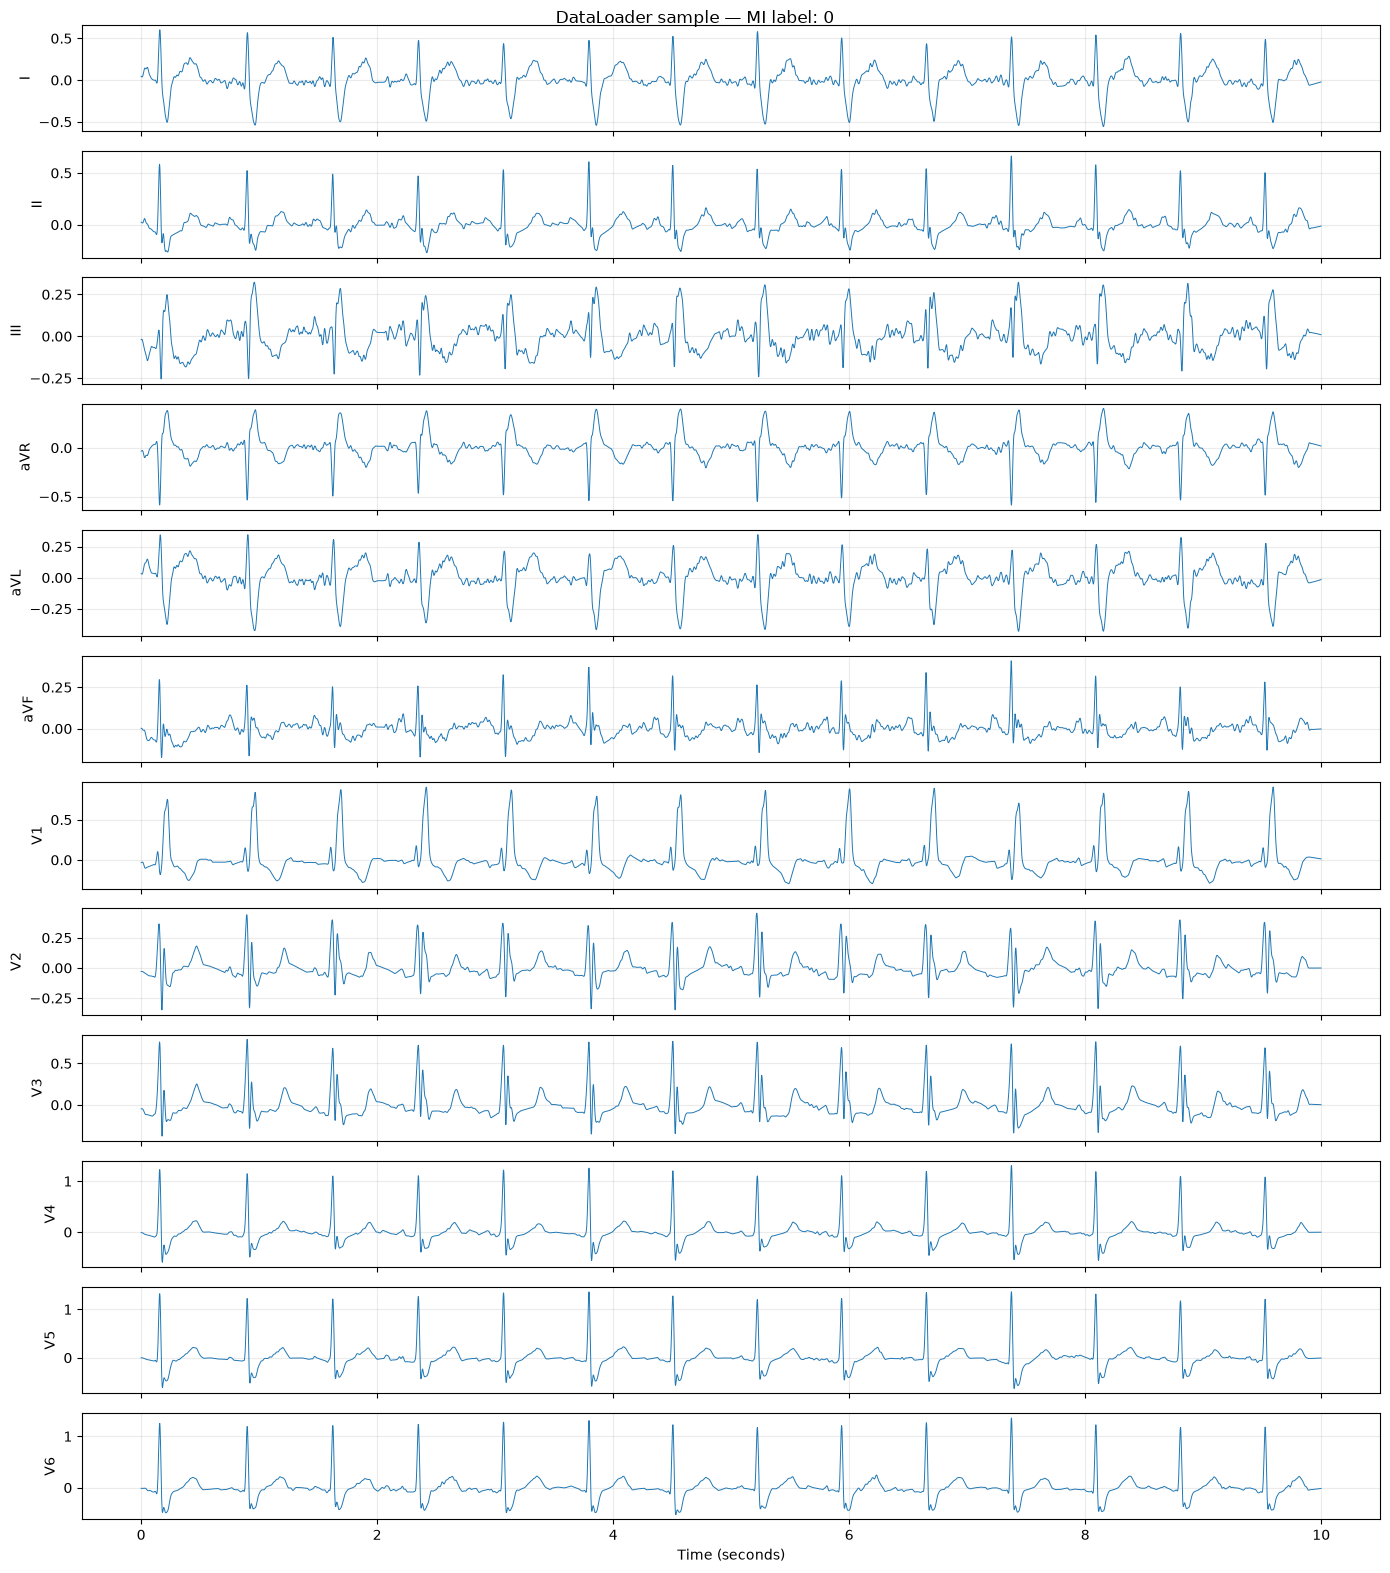

In [32]:
import matplotlib.pyplot as plt

sample_ecg = batch["ecg"][0].cpu().numpy()
sample_label = int(batch["label"][0].item())
lead_names = ["I", "II", "III", "aVR", "aVL", "aVF",
              "V1", "V2", "V3", "V4", "V5", "V6"]
time_axis = np.arange(sample_ecg.shape[1]) / 500.0

fig, axes = plt.subplots(12, 1, figsize=(14, 16), sharex=True)
for lead_idx, ax in enumerate(axes):
    ax.plot(time_axis, sample_ecg[lead_idx], linewidth=0.7)
    ax.set_ylabel(lead_names[lead_idx])
    ax.grid(True, alpha=0.25)
axes[-1].set_xlabel("Time (seconds)")
fig.suptitle(f"DataLoader sample — MI label: {sample_label}")
plt.tight_layout()
plt.show()

## STep 11: Save pipeline metadata

In [33]:
manifest = {
    "dataset": "PTB-XL",
    "signal_source": "filename_hr",
    "sampling_rate_hz": 500,
    "expected_signal_shape_wfdb": [5000, 12],
    "model_input_shape": [12, 5000],
    "target": "mi_label",
    "task": "binary MI vs non-MI classification",
    "splits": {
        name: int((labels["dataset_split"] == name).sum())
        for name in ["train", "validation", "test"]
    },
    "batch_size": BATCH_SIZE,
    "num_workers": NUM_WORKERS,
    "preprocessing_config_path": str(CONFIG_PATH),
    "preprocessing_config": PREPROCESSING_CONFIG,
    "normalization": "disabled; no fitted statistics used",
}

manifest_path = PROJECT_ROOT / "results" / "preprocessing" / "pytorch_data_manifest.json"
manifest_path.parent.mkdir(parents=True, exist_ok=True)
with manifest_path.open("w", encoding="utf-8") as file:
    json.dump(manifest, file, indent=4)

print("Saved:", manifest_path.resolve())

Saved: C:\Users\sintu\Desktop\Myocardial Infarction\results\preprocessing\pytorch_data_manifest.json
